# Slide-instance results: does the annealer beat greedy?

This notebook analyses `results/slide_instances_sa.csv`, the rerun of the nine
network-interdiction instances behind the D-Wave slides (slides 8–10 of
`S-T_NIP.pptx`). The original D-Wave result files were never stored, so every
number here comes from the committed CSV, which records the exact command that
produced it (issue #18).

For each instance and interdiction budget $B$ the CSV has:

* **`Opt_NIP`** — the exact optimum (Gurobi), i.e. the smallest max flow that
  survives cutting $B$ arcs;
* **`SA_NIP`** — the best budget-feasible sample among simulated annealing's 20
  lowest-energy samples (blank when none was feasible);
* **`SA_NIP_Greedy`** — the best of those 20 samples after greedy repair to
  exactly $B$ cuts;
* **`Greedy`** — plain greedy from nothing: cut the single most harmful arc,
  $B$ times;
* **`Random_Greedy`** — 20 random starts (each arc cut with probability $B/E$)
  after the same repair;
* **`lambda`, `lambda_lo`, `lambda_hi`** — the QUBO penalty and its exact valid
  window (issue #2).

The D-Wave (QA) column is empty: D-Wave runs are paused. Running this notebook
needs only pandas and matplotlib — no Gurobi license or D-Wave token (one
optional cell uses Gurobi if it is available).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:  # executed outside Jupyter
    display = print

# Works whether the notebook runs from notebooks/ or from the repo root.
REPO = Path.cwd() if (Path.cwd() / 'results').is_dir() else Path.cwd().parent
CSV = REPO / 'results' / 'slide_instances_sa.csv'

print('Provenance recorded in the CSV header:')
for line in CSV.read_text().splitlines():
    if line.startswith('#') and not line.startswith('# command'):
        print(' ', line)

Provenance recorded in the CSV header:
  # Generated by run_benchmark.py -- see README, "Regenerating the results CSV".
  # repo commit: 7604e445edf1e4a6aab857db74e8acb490992454-dirty
  # (annotated after the run: produced in a clean worktree at that commit; the '-dirty'
  #  flag came only from the untracked stderr capture file run.err -- no tracked file differed.)
  # generated (UTC): 2026-09-30T21:41:43+00:00
  # exact backend: gurobi
  # solver passes: sa
  # baselines: greedy, random (seed 0)
  # lambda = auto: the midpoint of the exact window (lambda_lo, lambda_hi); see the run_benchmark.py docstring.
  # empty lambda window (f not convex at B), baselines only: testcases/90_0.1.erdosflow B=10
  # qa columns are empty: that pass was not run here. Re-run with --solvers to fill them.


## 1. Load and derive the comparison metric

Every method is scored the way the slides score it: the flow reduction it
achieves as a fraction of the optimal flow reduction,

$$\text{ratio} = \frac{\text{maxflow} - \text{flow left by the method}}{\text{maxflow} - \text{Opt\_NIP}},$$

so **1.0 means optimal** and lower is worse. The slides label instances by their
QUBO size $V + 3E$.

In [2]:
raw = pd.read_csv(CSV, comment='#')
df = raw.copy()
df['family'] = df['instance'].str.extract(r'\.(\w+)flow$')[0].map(
    {'planar': 'planar', 'erdos': 'Erdős–Rényi', '2dnn': 'k-NN'})
df['qubo_vars'] = df['V'] + 3 * df['E']
df['label'] = df['qubo_vars'].astype(str) + ' (' + df['B'].astype(str) + ')'

optimal_reduction = df['maxflow'] - df['Opt_NIP']
# Ratio columns get their own names ("... ratio"), so the raw flow columns
# from the CSV -- Greedy, SA_NIP_Greedy, ... -- are never overwritten.
METHODS = {                       # ratio column -> CSV column
    'SA raw ratio': 'SA_NIP',
    'SA+repair ratio': 'SA_NIP_Greedy',
    'Greedy ratio': 'Greedy',
    'Random+repair ratio': 'Random_Greedy',
}
for name, column in METHODS.items():
    df[name] = (df['maxflow'] - df[column]) / optimal_reduction

FAMILIES = ['planar', 'Erdős–Rényi', 'k-NN']
display(df[['family', 'label', 'lambda', 'Opt_NIP'] + list(METHODS)].round(3))

,family,label,lambda,Opt_NIP,SA raw ratio,SA+repair ratio,Greedy ratio,Random+repair ratio
0,planar,914 (5),73.000,276.0,0.914,0.914,1.000,0.627
1,planar,914 (6),58.000,205.0,0.914,0.914,1.000,0.695
2,planar,914 (8),38.500,121.0,0.931,0.972,1.000,0.725
3,planar,914 (10),33.000,45.0,0.820,0.962,1.000,0.784
4,planar,1389 (5),50.500,286.0,NaN,0.598,1.000,0.851
5,planar,1389 (8),34.500,164.0,NaN,0.774,1.000,0.740
6,planar,1389 (10),26.500,104.0,0.834,0.864,1.000,0.657
7,planar,2339 (6),65.500,328.0,NaN,0.124,1.000,0.743
8,planar,2339 (10),33.500,120.0,0.112,0.702,1.000,0.702
9,Erdős–Rényi,1124 (5),65.500,358.0,0.915,0.915,1.000,0.649


## 2. Does simulated annealing plus repair beat plain greedy?

A row counts as "better" for whichever method leaves *less* flow. The one
Erdős–Rényi row with an empty λ window has no QUBO, so it has no SA result and is
excluded from the head-to-head.

In [3]:
with_qubo = df.dropna(subset=['SA_NIP_Greedy'])
diff = np.sign(with_qubo['Greedy'] - with_qubo['SA_NIP_Greedy'])  # +1: SA+repair left less flow

def head_to_head(frame, d):
    # A plain dict per row, so each column keeps its own dtype.
    return dict({
        'rows': len(frame),
        'SA+repair better': int((d > 0).sum()),
        'tie': int((d == 0).sum()),
        'Greedy better': int((d < 0).sum()),
        'Greedy optimal': int((frame['Greedy'] == frame['Opt_NIP']).sum()),
        'SA+repair optimal': int((frame['SA_NIP_Greedy'] == frame['Opt_NIP']).sum()),
        'mean ratio SA+repair': frame['SA+repair ratio'].mean(),
        'mean ratio Greedy': frame['Greedy ratio'].mean(),
    })

# One row per family (plus 'all'), so the count columns stay integers.
summary = pd.DataFrame(
    [head_to_head(with_qubo[with_qubo.family == f], diff[with_qubo.family == f])
     for f in FAMILIES] + [head_to_head(with_qubo, diff)],
    index=FAMILIES + ['all'])
display(summary.round(3))

print(f"Plain greedy is optimal on {int((df['Greedy'] == df['Opt_NIP']).sum())} "
      f"of {len(df)} rows (all rows, including the empty-window one).")

,rows,SA+repair better,tie,Greedy better,Greedy optimal,SA+repair optimal,mean ratio SA+repair,mean ratio Greedy
planar,9,0,0,9,9,0,0.758,1.000
Erdős–Rényi,8,0,5,3,6,3,0.970,0.996
k-NN,9,0,3,6,3,0,0.772,0.952
all,26,0,8,18,18,3,0.828,0.982


Plain greedy is optimal on 19 of 27 rows (all rows, including the empty-window one).


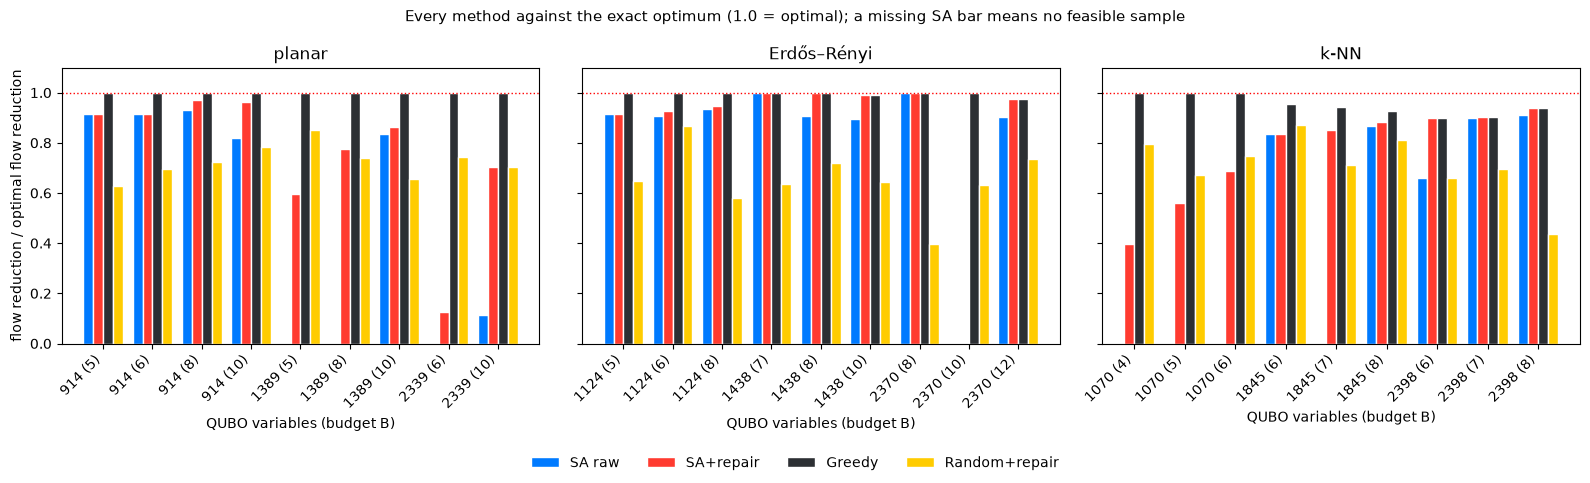

In [4]:
colors = {'SA raw ratio': '#007aff', 'SA+repair ratio': '#ff3b30',
          'Greedy ratio': '#2c2f33', 'Random+repair ratio': '#ffcc00'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
width = 0.2
for ax, family in zip(axes, FAMILIES):
    sub = df[df.family == family].reset_index(drop=True)
    x = np.arange(len(sub))
    for i, name in enumerate(METHODS):
        ax.bar(x + (i - 1.5) * width, sub[name], width, label=name.replace(' ratio', ''),
               color=colors[name], edgecolor='white')
    ax.axhline(1.0, color='r', linestyle=':', linewidth=1)
    ax.set_xticks(x, sub['label'], rotation=45, ha='right')
    ax.set_title(family)
    ax.set_xlabel('QUBO variables (budget B)')
axes[0].set_ylabel('flow reduction / optimal flow reduction')
axes[0].set_ylim(0, 1.1)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False)
fig.suptitle('Every method against the exact optimum (1.0 = optimal); '
             'a missing SA bar means no feasible sample', fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

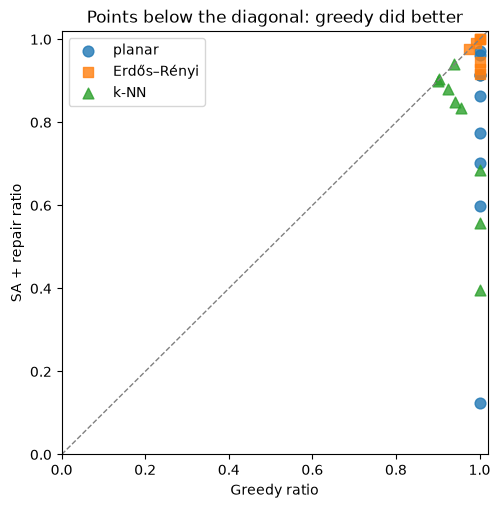

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
markers = {'planar': 'o', 'Erdős–Rényi': 's', 'k-NN': '^'}
for family in FAMILIES:
    sub = with_qubo[with_qubo.family == family]
    ax.scatter(sub['Greedy ratio'], sub['SA+repair ratio'], marker=markers[family],
               s=60, label=family, alpha=0.8)
ax.plot([0, 1.02], [0, 1.02], color='grey', linestyle='--', linewidth=1)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel('Greedy ratio')
ax.set_ylabel('SA + repair ratio')
ax.set_title('Points below the diagonal: greedy did better')
ax.legend()
plt.show()

## 3. Why does repairing SA's samples lose to greedy from nothing?

The repair step only adds or removes arcs until exactly $B$ are cut. When an SA
sample already has $B$ cuts, some of them wrong, repair cannot swap them out, so
it keeps the sample's mistakes. Greedy from nothing has no such anchor.

SA's samples still carry information about the instance: compare **SA + repair**
with **Random + repair**, which uses the same repair on samples that know
nothing but the budget.

In [6]:
sa_vs_random = np.sign(with_qubo['Random_Greedy'] - with_qubo['SA_NIP_Greedy'])
print(f"SA + repair vs Random + repair: SA better on {int((sa_vs_random > 0).sum())}, "
      f"tie on {int((sa_vs_random == 0).sum())}, random better on "
      f"{int((sa_vs_random < 0).sum())} of {len(with_qubo)} rows.")
print(f"Random + repair is optimal on {int((df['Random_Greedy'] == df['Opt_NIP']).sum())} rows.")

feasible = with_qubo.groupby('family')['SA_NIP'].apply(lambda s: f"{s.notna().sum()}/{len(s)}")
print('\nRaw SA had a budget-feasible sample among its 20 best on:')
display(feasible.reindex(FAMILIES).rename('rows'))

SA + repair vs Random + repair: SA better on 19, tie on 1, random better on 6 of 26 rows.
Random + repair is optimal on 0 rows.

Raw SA had a budget-feasible sample among its 20 best on:


family
planar         6/9
Erdős–Rényi    8/8
k-NN           5/9
Name: rows, dtype: str

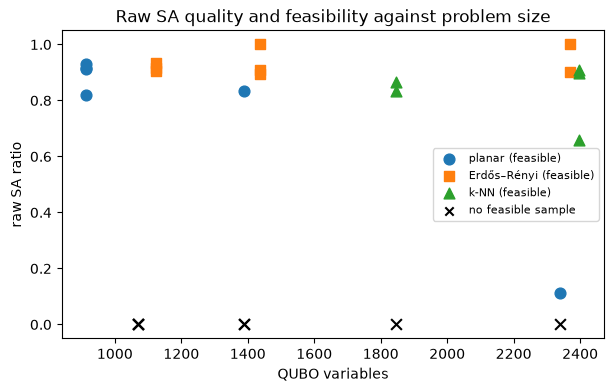

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for family in FAMILIES:
    sub = with_qubo[with_qubo.family == family]
    feasible_rows = sub['SA_NIP'].notna()
    ax.scatter(sub.loc[feasible_rows, 'qubo_vars'], sub.loc[feasible_rows, 'SA raw ratio'],
               marker=markers[family], s=60, label=f'{family} (feasible)')
    ax.scatter(sub.loc[~feasible_rows, 'qubo_vars'], np.zeros((~feasible_rows).sum()),
               marker='x', s=60, color='k')
ax.scatter([], [], marker='x', color='k', label='no feasible sample')
ax.set_xlabel('QUBO variables')
ax.set_ylabel('raw SA ratio')
ax.set_ylim(-0.05, 1.05)
ax.set_title('Raw SA quality and feasibility against problem size')
ax.legend(fontsize=8)
plt.show()

## 4. Do we reproduce the slides?

The slides' numbers survive only as figures, so the table below is **pinned
evidence read off slides 8–10 by eye (about ±0.01)**, not recomputed data. A
blank is a bar the slide drew at zero, meaning no feasible sample. The slides'
"QA-Greedy" and "SA-Greedy" bars were identical on every row, so one column
covers both.

In [8]:
# Read off S-T_NIP.pptx slides 8-10 (±0.01). Order within each family follows
# the slides' x-axis.
SLIDES = pd.DataFrame({
    'instance': (['testcases/50.planarflow'] * 4 + ['testcases/75.planarflow'] * 3
                 + ['testcases/125.planarflow'] * 2
                 + ['testcases/50_0.15.erdosflow'] * 3 + ['testcases/70_0.1.erdosflow'] * 3
                 + ['testcases/90_0.1.erdosflow'] * 3
                 + ['testcases/50_5.2dnnflow'] * 3 + ['testcases/75_6.2dnnflow'] * 3
                 + ['testcases/100_6.2dnnflow'] * 3),
    'B': [5, 6, 8, 10, 5, 8, 10, 6, 10,
          5, 6, 8, 7, 8, 10, 8, 10, 12,
          4, 5, 6, 6, 7, 8, 6, 7, 8],
    'slide_QA': [0.91, 0.91, 0.87, 0.92, 0.60, 0.72, 0.73, np.nan, np.nan,
                 0.89, 0.90, 0.95, 0.97, 0.83, 0.78, 0.86, 0.80, 0.70,
                 0.37, np.nan, 0.47, np.nan, np.nan, 0.86, 0.52, 0.90, 0.84],
    'slide_SA': [0.91, 0.91, 0.93, 0.85, np.nan, np.nan, 0.82, 0.16, np.nan,
                 0.91, 0.93, 0.93, 1.00, 1.00, 0.89, 0.90, 0.95, 0.86,
                 np.nan, np.nan, np.nan, 0.81, 0.79, 0.86, 0.66, 0.90, 0.90],
    'slide_repaired': [1.0] * 9
                      + [1.0, 1.0, 1.0, 1.0, 1.0, 0.99, 1.0, 1.0, 0.97]
                      + [1.0, 1.0, 1.0, 0.95, 0.94, 0.93, 0.90, 0.90, 0.94],
})
cmp = df.merge(SLIDES, on=['instance', 'B'], validate='one_to_one')
cmp['|slide repaired − our Greedy|'] = (cmp['slide_repaired'] - cmp['Greedy ratio']).abs()
cmp['|slide repaired − our SA+repair|'] = (cmp['slide_repaired'] - cmp['SA+repair ratio']).abs()
display(cmp[['family', 'label', 'slide_repaired', 'Greedy ratio', 'SA+repair ratio',
             '|slide repaired − our Greedy|', '|slide repaired − our SA+repair|']].round(3))

print(f"Largest gap, slide 'repaired' vs our plain Greedy:   "
      f"{cmp['|slide repaired − our Greedy|'].max():.3f}")
print(f"Largest gap, slide 'repaired' vs our SA + repair:    "
      f"{cmp['|slide repaired − our SA+repair|'].max():.3f}")

,family,label,slide_repaired,Greedy ratio,SA+repair ratio,|slide repaired − our Greedy|,|slide repaired − our SA+repair|
0,planar,914 (5),1.00,1.000,0.914,0.000,0.086
1,planar,914 (6),1.00,1.000,0.914,0.000,0.086
2,planar,914 (8),1.00,1.000,0.972,0.000,0.028
3,planar,914 (10),1.00,1.000,0.962,0.000,0.038
4,planar,1389 (5),1.00,1.000,0.598,0.000,0.402
5,planar,1389 (8),1.00,1.000,0.774,0.000,0.226
6,planar,1389 (10),1.00,1.000,0.864,0.000,0.136
7,planar,2339 (6),1.00,1.000,0.124,0.000,0.876
8,planar,2339 (10),1.00,1.000,0.702,0.000,0.298
9,Erdős–Rényi,1124 (5),1.00,1.000,0.915,0.000,0.085


Largest gap, slide 'repaired' vs our plain Greedy:   0.006
Largest gap, slide 'repaired' vs our SA + repair:    0.876


The slides' repaired values match **plain greedy** to reading precision on every
row, and do not match our SA + repair. That is issue #12: before it was fixed,
`improve_dwave_solution()` looked samples up by integer index while PyQUBO keys
them `'x_0'`, `'x_1'`, …, so it never saw a cut and always repaired from an empty
solution — which *is* plain greedy. It is also why the slides' QA-Greedy and
SA-Greedy bars were identical. The raw QA and SA bars were real samples.

Raw SA is stochastic and the original seeds were not kept, so our raw SA can only
match the slides' in distribution:

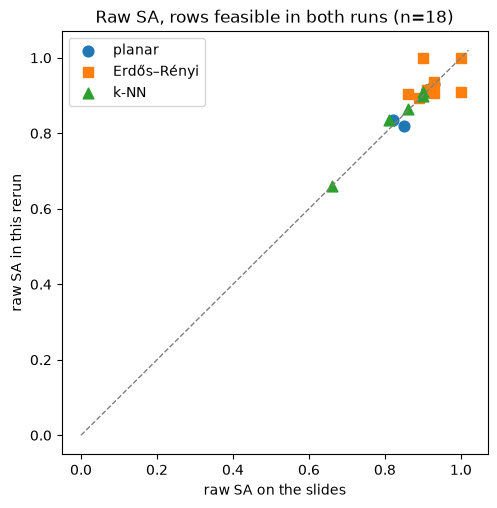

Median absolute difference: 0.005


In [9]:
both = cmp.dropna(subset=['slide_SA', 'SA raw ratio'])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for family in FAMILIES:
    sub = both[both.family == family]
    ax.scatter(sub['slide_SA'], sub['SA raw ratio'], marker=markers[family], s=60, label=family)
ax.plot([0, 1.02], [0, 1.02], color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('raw SA on the slides')
ax.set_ylabel('raw SA in this rerun')
ax.set_title(f'Raw SA, rows feasible in both runs (n={len(both)})')
ax.legend()
plt.show()
print('Median absolute difference:',
      round(float((both['slide_SA'] - both['SA raw ratio']).abs().median()), 3))

## 5. The penalty window λ

The QUBO's budget penalty is linear, so only a window of λ values makes its
ground state the true optimum. `run_benchmark.py` computes that window exactly
and uses its midpoint. Narrow windows explain why hand-tuned λ was fragile; an
empty window (lower end above upper end) means **no** λ works for that row.

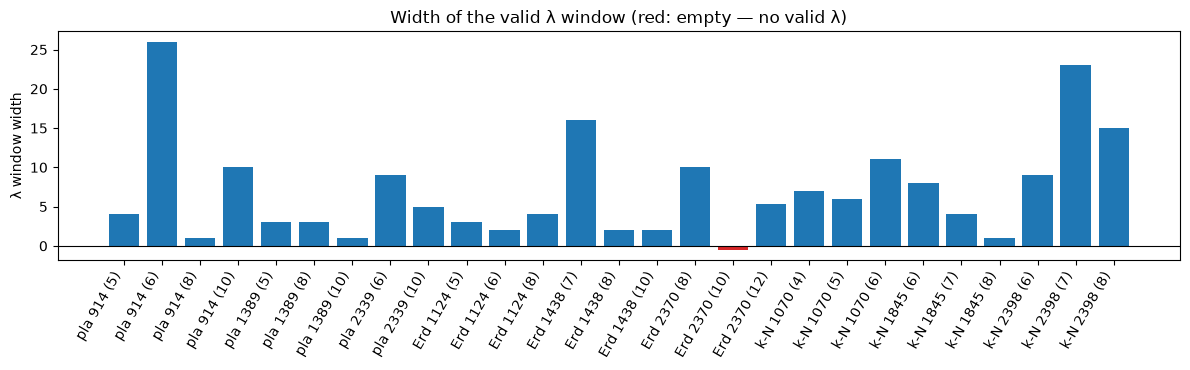

Non-empty windows: 26 of 27; median width 5.17; 6 are 2 or narrower.


,family,label,lambda_lo,lambda_hi,Opt_NIP,Greedy
16,Erdős–Rényi,2370 (10),36.5,36.0,156.0,156


In [10]:
w = df.assign(width=df['lambda_hi'] - df['lambda_lo'])
fig, ax = plt.subplots(figsize=(12, 3.8))
bar_colors = ['#d62728' if v <= 0 else '#1f77b4' for v in w['width']]
ax.bar(np.arange(len(w)), w['width'], color=bar_colors)
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xticks(np.arange(len(w)), w['family'].str[:3] + ' ' + w['label'], rotation=60, ha='right')
ax.set_ylabel('λ window width')
ax.set_title('Width of the valid λ window (red: empty — no valid λ)')
fig.tight_layout()
plt.show()

nonempty = w[w['width'] > 0]
print(f"Non-empty windows: {len(nonempty)} of {len(w)}; median width "
      f"{nonempty['width'].median():.2f}; {int((nonempty['width'] <= 2).sum())} are 2 or narrower.")
display(w.loc[w['width'] <= 0, ['family', 'label', 'lambda_lo', 'lambda_hi', 'Opt_NIP', 'Greedy']])

**Optional (needs a full Gurobi license).** Why the Erdős–Rényi 90-node row at
$B=10$ has no valid λ: the optimal surviving flow $f(k)$ with $k$ cuts is not
convex there. The 10th cut saves less than the average of the 11th and 12th, so
any per-cut price that makes the 10th worth taking also makes the pair worth
taking.

In [11]:
import sys
sys.path.insert(0, str(REPO))  # the repo's modules, when run from notebooks/
try:
    import network_interdiction as ni
    import run_benchmark as rb
    import contextlib, io
    g, s, t = ni.read_flow_file(str(REPO / 'testcases' / '90_0.1.erdosflow'))
    with contextlib.redirect_stdout(io.StringIO()):  # solve_nip_gurobi prints each solve
        curve = rb.optimum_curve('gurobi', g, s, t, 10)
    ks = list(range(7, 14))
    print('k        :', ks)
    print('f(k)     :', [curve[k] for k in ks])
    print('saving   :', ['-'] + [curve[k - 1] - curve[k] for k in ks[1:]])
    print('window at B=10:', rb.lambda_window(curve, 10))
except Exception as e:  # no Gurobi license, or not run from the repo
    print(f'Skipped (needs Gurobi and the repo modules): {type(e).__name__}: {e}')

k        : [7, 8, 9, 10, 11, 12, 13]
f(k)     : [282, 232, 192, 156, 125, 83, 52]
saving   : ['-', 50, 40, 36, 31, 42, 31]
window at B=10: (36.5, 36.0)


## 6. QUBO energy reached by SA

Energies are negative, so the ratio `SA_QUBO / Opt_QUBO` is 1 at the ground
state and below 1 when SA stops short of it.

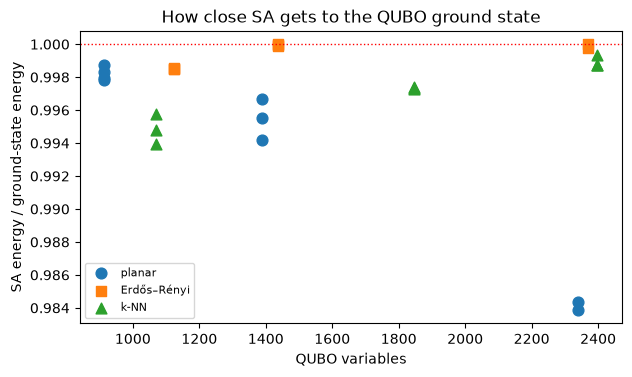

SA reached the exact ground-state energy on 2 of 26 rows.


In [12]:
e = with_qubo.assign(energy_ratio=with_qubo['SA_QUBO'] / with_qubo['Opt_QUBO'])
fig, ax = plt.subplots(figsize=(7, 3.8))
for family in FAMILIES:
    sub = e[e.family == family]
    ax.scatter(sub['qubo_vars'], sub['energy_ratio'], marker=markers[family], s=60, label=family)
ax.axhline(1.0, color='r', linestyle=':', linewidth=1)
ax.set_xlabel('QUBO variables')
ax.set_ylabel('SA energy / ground-state energy')
ax.set_title('How close SA gets to the QUBO ground state')
ax.legend(fontsize=8)
plt.show()
print(f"SA reached the exact ground-state energy on "
      f"{int(np.isclose(e['SA_QUBO'], e['Opt_QUBO']).sum())} of {len(e)} rows.")

## Conclusions

* On these instances, simulated annealing followed by greedy repair **never beats
  plain greedy** (section 2). Plain greedy is optimal on every planar row and most
  Erdős–Rényi rows; the k-NN family is the only one where greedy leaves a gap,
  so it is where a better method could show a benefit.
* The slides' "greedy post-processing recovers optimal solutions" result is
  **plain greedy's result** (section 4): the repair step at the time ignored the
  annealer's sample (issue #12). The proposal's statement should be restated
  accordingly.
* SA's samples do carry information — SA + repair usually beats random starts
  with the same repair (section 3) — but greedy repair is the wrong way to use
  them, because it cannot swap out wrong cuts.
* The linear budget penalty admits only a narrow λ window, and on one slide row
  none at all (section 5). That is the evidence for the linear-versus-squared
  penalty decision in issue #2.

Next comparisons worth adding: the LP-relaxation and Benders baselines (#15), and
the D-Wave column once runs resume (#18).